<a href="https://colab.research.google.com/github/keolala/Keola-Mahatma-XIINTL-Hasil-Laporan-Praktikum-AVD-Dataset-/blob/main/Dataset_E_Commerce_Sales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Laporan Analisis Penjualan E-Commerce

Analisis ini bertujuan untuk mengevaluasi performa penjualan/promosi produk periode terakhir serta menyusun strategi bisnis ke depan.
```

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Memuat dan Membersihkan Data
file_path = '/content/data.csv'
try:
    df = pd.read_csv(file_path, encoding='latin-1')
    print("Data awal berhasil dimuat dengan ukuran:", df.shape)
except Exception as e:
    print("Gagal memuat data:", e)

# Memeriksa data kosong & duplikat
print("\nJumlah data kosong per kolom:")
print(df.isnull().sum())
print("\nJumlah data duplikat:", df.duplicated().sum())

# Proses Pembersihan
df = df.drop_duplicates().copy()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

df = df.dropna(subset=["InvoiceNo", "Description", "InvoiceDate", "Quantity", "UnitPrice"])

# Memisahkan Transaksi Pembatalan dan Penjualan Bersih
pembatalan = df[df["InvoiceNo"].astype(str).str.startswith("C")].copy()
penjualan = df[(~df["InvoiceNo"].astype(str).str.startswith("C")) & (df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()

penjualan["TotalSales"] = penjualan["Quantity"] * penjualan["UnitPrice"]
penjualan["Month"] = penjualan["InvoiceDate"].dt.to_period("M").astype(str)

print("\n--- Setelah Pembersihan ---")
print("Ukuran Data Penjualan Bersih:", penjualan.shape)
print("Jumlah Transaksi Pembatalan:", len(pembatalan))

Data awal berhasil dimuat dengan ukuran: (541909, 8)

Jumlah data kosong per kolom:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Jumlah data duplikat: 5268

--- Setelah Pembersihan ---
Ukuran Data Penjualan Bersih: (524878, 10)
Jumlah Transaksi Pembatalan: 9251


```markdown
## 2. Analisis Statistik Deskriptif Kunci
Berikut adalah metrik utama dari transaksi penjualan bersih:
```

In [ ]:
nilai_transaksi = penjualan.groupby("InvoiceNo")["TotalSales"].sum()

print("1. Total Penjualan Bersih: £{:,.2f}".format(penjualan["TotalSales"].sum()))
print("2. Rata-rata Nilai Transaksi: £{:,.2f}".format(nilai_transaksi.mean()))
print("3. Median Nilai Transaksi: £{:,.2f}".format(nilai_transaksi.median()))
print("4. Total Barang Terjual:", int(penjualan["Quantity"].sum()))
print("5. Wilayah (Negara) Penjualan Tertinggi:")
display(penjualan.groupby("Country")["TotalSales"].sum().nlargest(3))

1. Total Penjualan Bersih: £10,642,110.80
2. Rata-rata Nilai Transaksi: £533.17
3. Median Nilai Transaksi: £303.30
4. Total Barang Terjual: 5572420
5. Wilayah (Negara) Penjualan Tertinggi:


,TotalSales
Country,
United Kingdom,9001744.094
Netherlands,285446.340
EIRE,283140.520


```markdown
## 3. Visualisasi Deteksi Outlier (Boxplot)
Kami menganalisis pencilan (outlier) pada jumlah kuantitas barang terjual menggunakan aturan IQR.
```

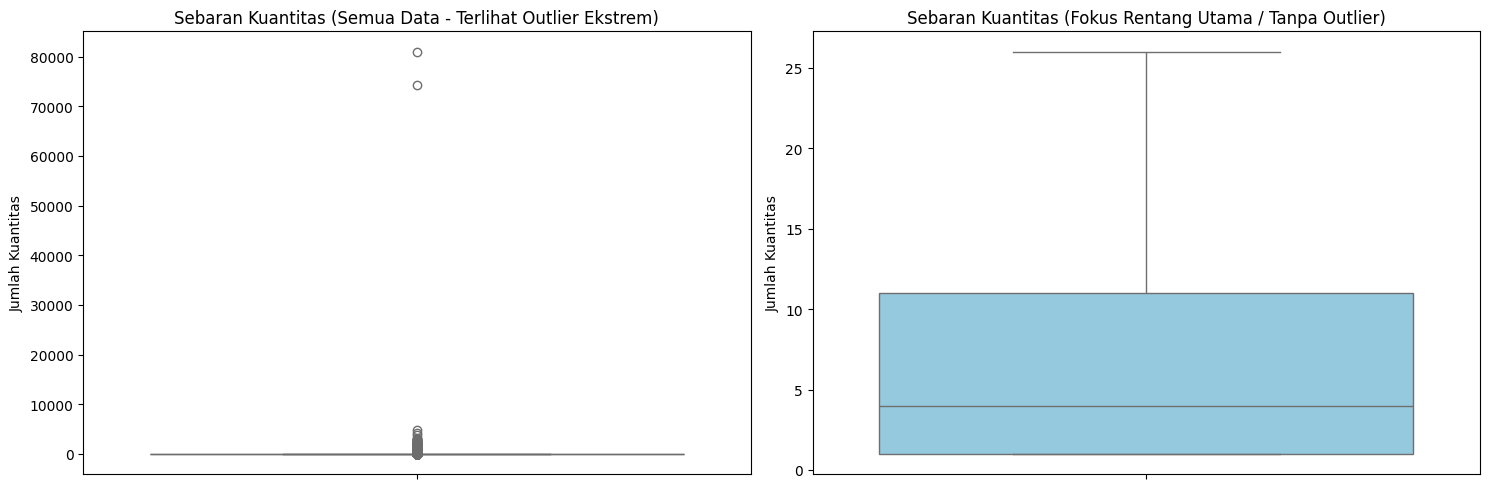

Batas Atas Outlier: 26.0 unit
Jumlah data terdeteksi outlier: 27111 baris


In [ ]:
# Hitung Outlier menggunakan batas IQR
Q1 = penjualan["Quantity"].quantile(0.25)
Q3 = penjualan["Quantity"].quantile(0.75)
IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier = penjualan[(penjualan["Quantity"] < batas_bawah) | (penjualan["Quantity"] > batas_atas)]

# Membuat Boxplot berdampingan
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=penjualan, y="Quantity", ax=axes[0], color='salmon')
axes[0].set_title("Sebaran Kuantitas (Semua Data - Terlihat Outlier Ekstrem)")
axes[0].set_ylabel("Jumlah Kuantitas")

sns.boxplot(data=penjualan, y="Quantity", ax=axes[1], showfliers=False, color='skyblue')
axes[1].set_title("Sebaran Kuantitas (Fokus Rentang Utama / Tanpa Outlier)")
axes[1].set_ylabel("Jumlah Kuantitas")

plt.tight_layout()
plt.show()

print(f"Batas Atas Outlier: {batas_atas} unit")
print(f"Jumlah data terdeteksi outlier: {len(outlier)} baris")

```markdown
### Detail Transaksi Outlier Paling Ekstrem
Untuk memverifikasi bahwa diagram di atas valid, berikut adalah data transaksi dengan kuantitas pembelian terbesar (Top 5 Outliers):
```

In [ ]:
# Menampilkan 5 transaksi dengan kuantitas pembelian terbesar
top_ekstrem = penjualan.nlargest(5, "Quantity")
display(top_ekstrem[["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "TotalSales", "Country"]])

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,TotalSales,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,United Kingdom
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,United Kingdom
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,1008.00,United Kingdom
206121,554868,22197,SMALL POPCORN HOLDER,4300,0.72,3096.00,United Kingdom
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.82,3202.92,United Kingdom


```markdown
## 5. Visualisasi & Panduan Membaca Diagram

Berikut adalah grafik analisis individual yang dipisah per sel untuk mempermudah dokumentasi presentasi Anda.
```

```markdown
### **Grafik 1: Deteksi Outlier (Boxplot Kuantitas Semua Data)**
Diagram ini digunakan untuk melihat apakah ada transaksi dengan kuantitas yang tidak wajar di dalam dataset.
```

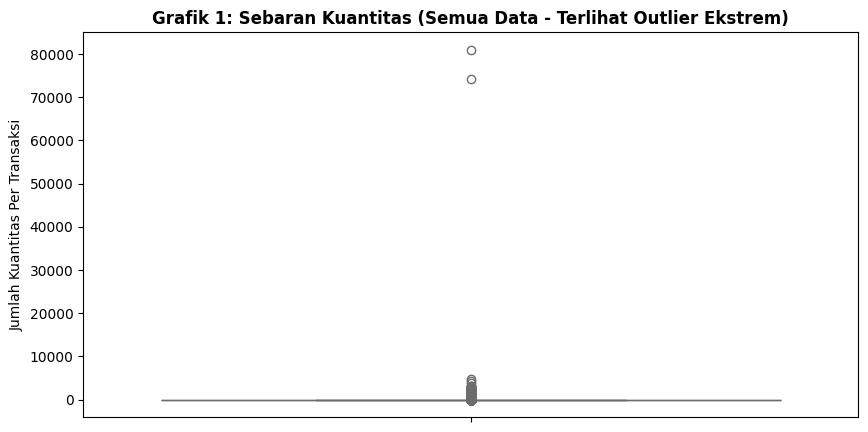

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.boxplot(data=penjualan, y="Quantity", color='salmon')
plt.title("Grafik 1: Sebaran Kuantitas (Semua Data - Terlihat Outlier Ekstrem)", fontsize=12, fontweight='bold')
plt.ylabel("Jumlah Kuantitas Per Transaksi")
plt.show()

```markdown
* **Cara Membaca**: Sumbu vertikal (Y) menunjukkan kuantitas produk per baris transaksi. Terlihat kotak biru utama tertekan di bagian paling bawah dekat angka 0, sementara beberapa titik merah (pencilan) melambung sangat tinggi hingga mendekati angka **80.000**.
* **Insight**: Mayoritas transaksi pelanggan bernilai kecil, namun terdapat beberapa transaksi berskala raksasa (grosir/B2B) yang sangat ekstrim seperti pembelian **80.995 unit** produk sekaligus.
```

```markdown
### **Analisis Tambahan: Mengapa Titik Data Mengelompok di Rentang Tertentu (Tidak Dominan Kiri/Kanan)?**

Jika diperhatikan pada **Grafik 5 (Scatter Plot)**, persebaran data tampak mengumpul rapat di area kiri-bawah menuju tengah dan tidak menyebar secara ekstrem secara horizontal ke kanan atau kiri karena beberapa faktor berikut:

1. **Ketimpangan Skala Data (Efek Outlier Ekstrem)**:
   * Rentang kuantitas barang dalam dataset berkisar antara **1 hingga lebih dari 80.000 unit** (akibat transaksi grosir raksasa).
   * Namun, **95%+ transaksi ritel normal** hanya memiliki kuantitas pembelian berkisar antara **1 hingga 11 unit**.
   * Saat digambarkan dalam skala sumbu X yang harus menampung nilai hingga puluhan ribu, seluruh data ritel normal (1-11 unit) secara visual akan terkompresi dan menumpuk di area paling kiri dekat angka 0.

2. **Representasi Sampel Acak (*Sampling Bias*)**:
   * Grafik ini menggunakan sampel acak sebanyak 3.000 transaksi dari total lebih dari 500.000 baris data.
   * Karena populasi didominasi oleh transaksi ritel kecil, maka secara probabilitas sampel yang terpilih hampir seluruhnya adalah transaksi reguler. Hal ini membuat titik-titik pada grafik terpusat di klaster bawah-tengah secara konsisten.

3. **Hubungan Linier Matematis (`TotalSales = Quantity * UnitPrice`)**:
   * Secara matematis, nilai transaksi berbanding lurus dengan kuantitas produk yang dibeli.
   * Data tidak mungkin berada di area **kanan-bawah** (membeli kuantitas sangat tinggi tetapi harga totalnya nol/sangat murah).
   * Data juga sangat jarang berada di area **kiri-atas** (membeli kuantitas sangat sedikit tetapi harga totalnya sangat tinggi, kecuali untuk barang mewah yang sangat mahal).
   * Batasan logis ini memaksa titik-titik data untuk membentuk garis diagonal yang rapat dari sudut kiri bawah menuju kanan atas.
```

```markdown
### **Grafik 2: Boxplot Distribusi Utama (Tanpa Outlier)**
Diagram ini memfokuskan visualisasi pada pola belanja mayoritas pelanggan umum dengan menyaring transaksi ekstrim.
```

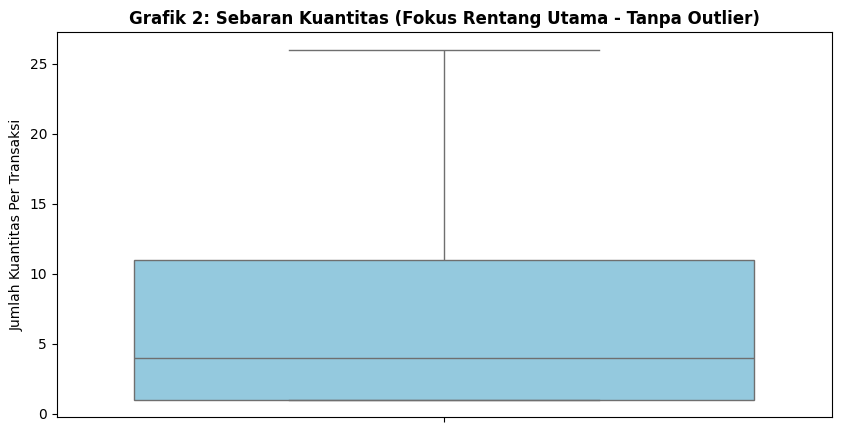

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=penjualan, y="Quantity", showfliers=False, color='skyblue')
plt.title("Grafik 2: Sebaran Kuantitas (Fokus Rentang Utama - Tanpa Outlier)", fontsize=12, fontweight='bold')
plt.ylabel("Jumlah Kuantitas Per Transaksi")
plt.show()

```markdown
* **Cara Membaca**: Grafik ini menyembunyikan pencilan ekstrim di atas batas 26 unit. Kotak biru menunjukkan Interquartile Range (rentang 50% data tengah), dengan garis tengah di dalam kotak sebagai nilai median belanja.
* **Insight**: Mayoritas transaksi ritel normal sangat konsisten dan berkisar di angka yang relatif kecil, yaitu antara **1 hingga 11 unit** saja per item.
```

```markdown
### **Grafik 3: Top 10 Produk Terlaris (Bar Chart)**
Diagram ini mengidentifikasi produk yang menyumbangkan pendapatan kotor terbesar bagi e-commerce.
```

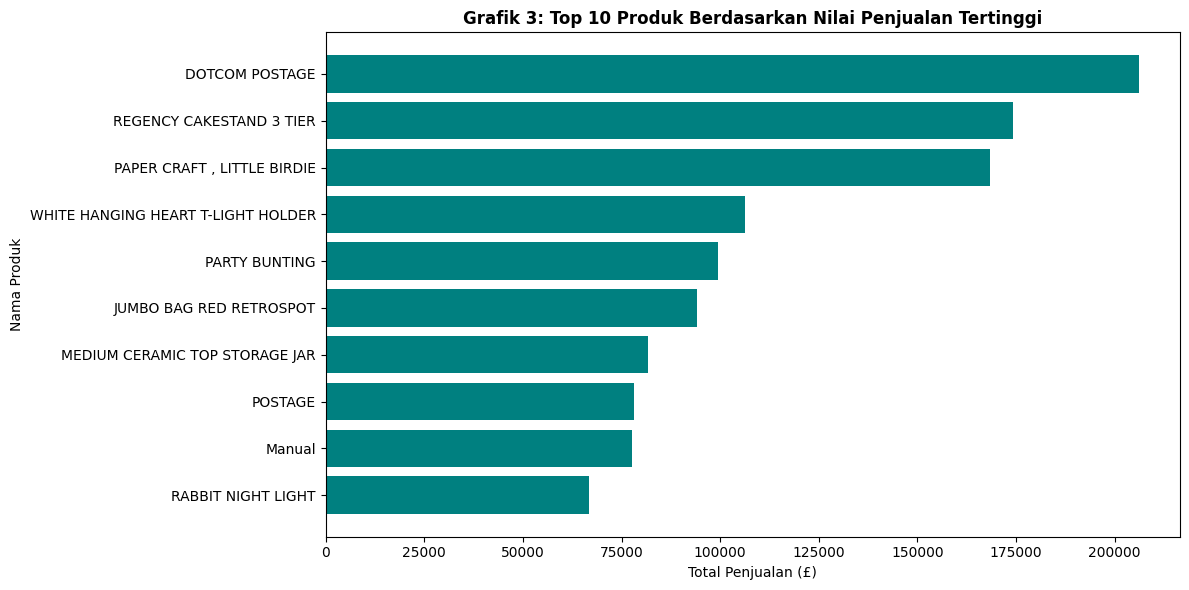

In [ ]:
top_produk = penjualan.groupby("Description")["TotalSales"].sum().nlargest(10).sort_values()
plt.figure(figsize=(12, 6))
plt.barh(top_produk.index, top_produk.values, color='teal')
plt.title("Grafik 3: Top 10 Produk Berdasarkan Nilai Penjualan Tertinggi", fontsize=12, fontweight='bold')
plt.xlabel("Total Penjualan (£)")
plt.ylabel("Nama Produk")
plt.tight_layout()
plt.show()

```markdown
* **Cara Membaca**: Semakin panjang batang horizontal ke arah kanan, semakin besar akumulasi nilai penjualan produk tersebut dalam satuan Poundsterling (£).
* **Insight**: Produk **"REGENCY CAKESTAND 3 TIER"** memimpin penjualan dengan total omset mencapai lebih dari **£174.000**, disusul oleh **"PAPER CRAFT, LITTLE BIRDIE"** di peringkat kedua.
```

```markdown
### **Grafik 4: Tren Penjualan Bulanan (Line Chart)**
Diagram garis ini digunakan untuk memantau fluktuasi kinerja penjualan perusahaan dari waktu ke waktu.
```

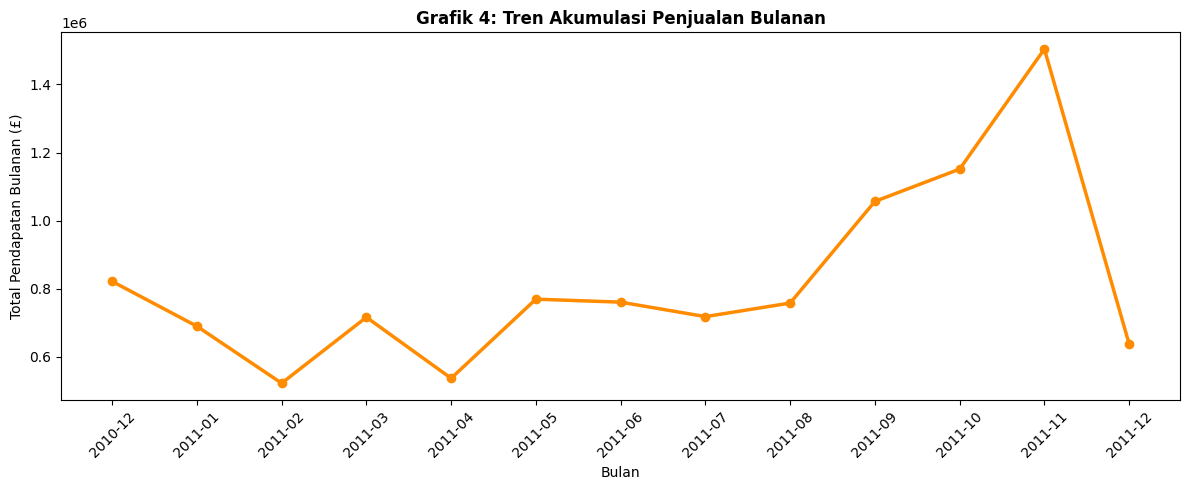

In [ ]:
tren_bulanan = penjualan.groupby("Month")["TotalSales"].sum()
plt.figure(figsize=(12, 5))
plt.plot(tren_bulanan.index, tren_bulanan.values, marker='o', color='darkorange', linewidth=2.5)
plt.title("Grafik 4: Tren Akumulasi Penjualan Bulanan", fontsize=12, fontweight='bold')
plt.xlabel("Bulan")
plt.ylabel("Total Pendapatan Bulanan (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

```markdown
* **Cara Membaca**: Titik-titik pada garis menunjukkan total pendapatan bulanan. Arah naik-turun garis menggambarkan naik-turunnya performa bisnis.
* **Insight**: Penjualan cenderung stabil sepanjang tahun di angka £500k-£800k, namun melonjak drastis memasuki kuartal keempat (Q4) dengan puncaknya pada **November sebesar £1,50M** akibat pola belanja musiman akhir tahun (*holiday season*).
```

```markdown
### **Grafik 5: Hubungan Kuantitas vs Nilai Penjualan (Scatter Plot)**
Diagram tebar untuk menganalisis hubungan timbal balik antara volume barang belanja dengan nilai uang transaksi.
```

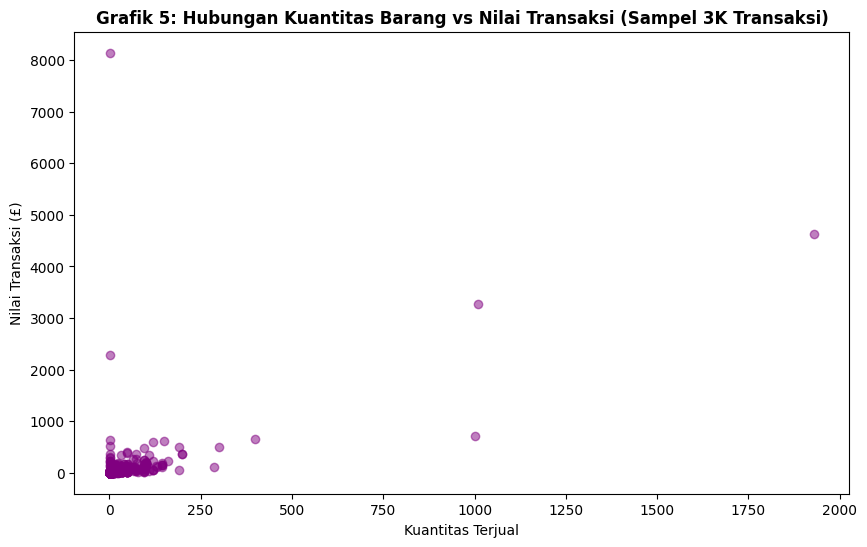

In [ ]:
sampel_data = penjualan.sample(n=min(3000, len(penjualan)), random_state=42)
plt.figure(figsize=(10, 6))
plt.scatter(sampel_data["Quantity"], sampel_data["TotalSales"], alpha=0.5, color='purple')
plt.title("Grafik 5: Hubungan Kuantitas Barang vs Nilai Transaksi (Sampel 3K Transaksi)", fontsize=12, fontweight='bold')
plt.xlabel("Kuantitas Terjual")
plt.ylabel("Nilai Transaksi (£)")
plt.show()

```markdown
* **Cara Membaca**: Setiap titik mewakili satu item transaksi sampel. Pola titik yang condong naik ke kanan atas membuktikan adanya hubungan yang linier.
* **Insight**: Semakin besar volume kuantitas barang yang dipesan pelanggan, maka total pengeluaran belanja (£) akan meningkat secara linier. Konsentrasi transaksi terpadat berada di area kiri bawah (ritel).
```

```markdown
### **Grafik 6: Distribusi Frekuensi Kuantitas Pembelian (Histogram)**
Diagram ini digunakan untuk memahami seberapa sering jumlah kuantitas tertentu dibeli oleh pelanggan dalam satu baris transaksi.
```

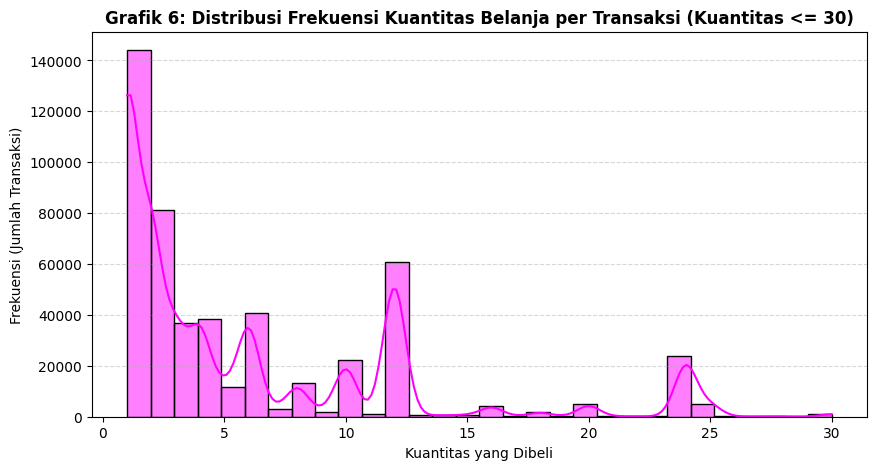

In [ ]:
plt.figure(figsize=(10, 5))
# Membatasi kuantitas hingga 30 agar visualisasi distribusi bins terlihat jelas dan tidak terganggu outlier ekstrem
sns.histplot(data=penjualan[penjualan["Quantity"] <= 30], x="Quantity", bins=30, kde=True, color='magenta')
plt.title("Grafik 6: Distribusi Frekuensi Kuantitas Belanja per Transaksi (Kuantitas <= 30)", fontsize=12, fontweight='bold')
plt.xlabel("Kuantitas yang Dibeli")
plt.ylabel("Frekuensi (Jumlah Transaksi)")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

```markdown
* **Cara Membaca**: Sumbu X menunjukkan jumlah kuantitas barang yang dibeli per item transaksi, sedangkan sumbu Y mewakili seberapa sering kuantitas tersebut muncul dalam seluruh transaksi. Garis melengkung halus (KDE) menunjukkan estimasi kepadatan distribusi.
* **Insight**: Terjadi konsentrasi yang sangat padat pada pembelian kuantitas **1, 2, dan 12 unit**. Hal ini mengindikasikan bahwa pembeli ritel cenderung membeli dalam jumlah satuan minimum atau paket lusinan (12 unit).
```

```markdown
## 4. Dashboard Ringkas Penjualan E-Commerce
Berikut adalah dashboard visualisasi interaktif yang menggabungkan 4 metrik dan grafik utama ke dalam satu tampilan terpadu untuk memudahkan pengambilan keputusan manajemen.
```

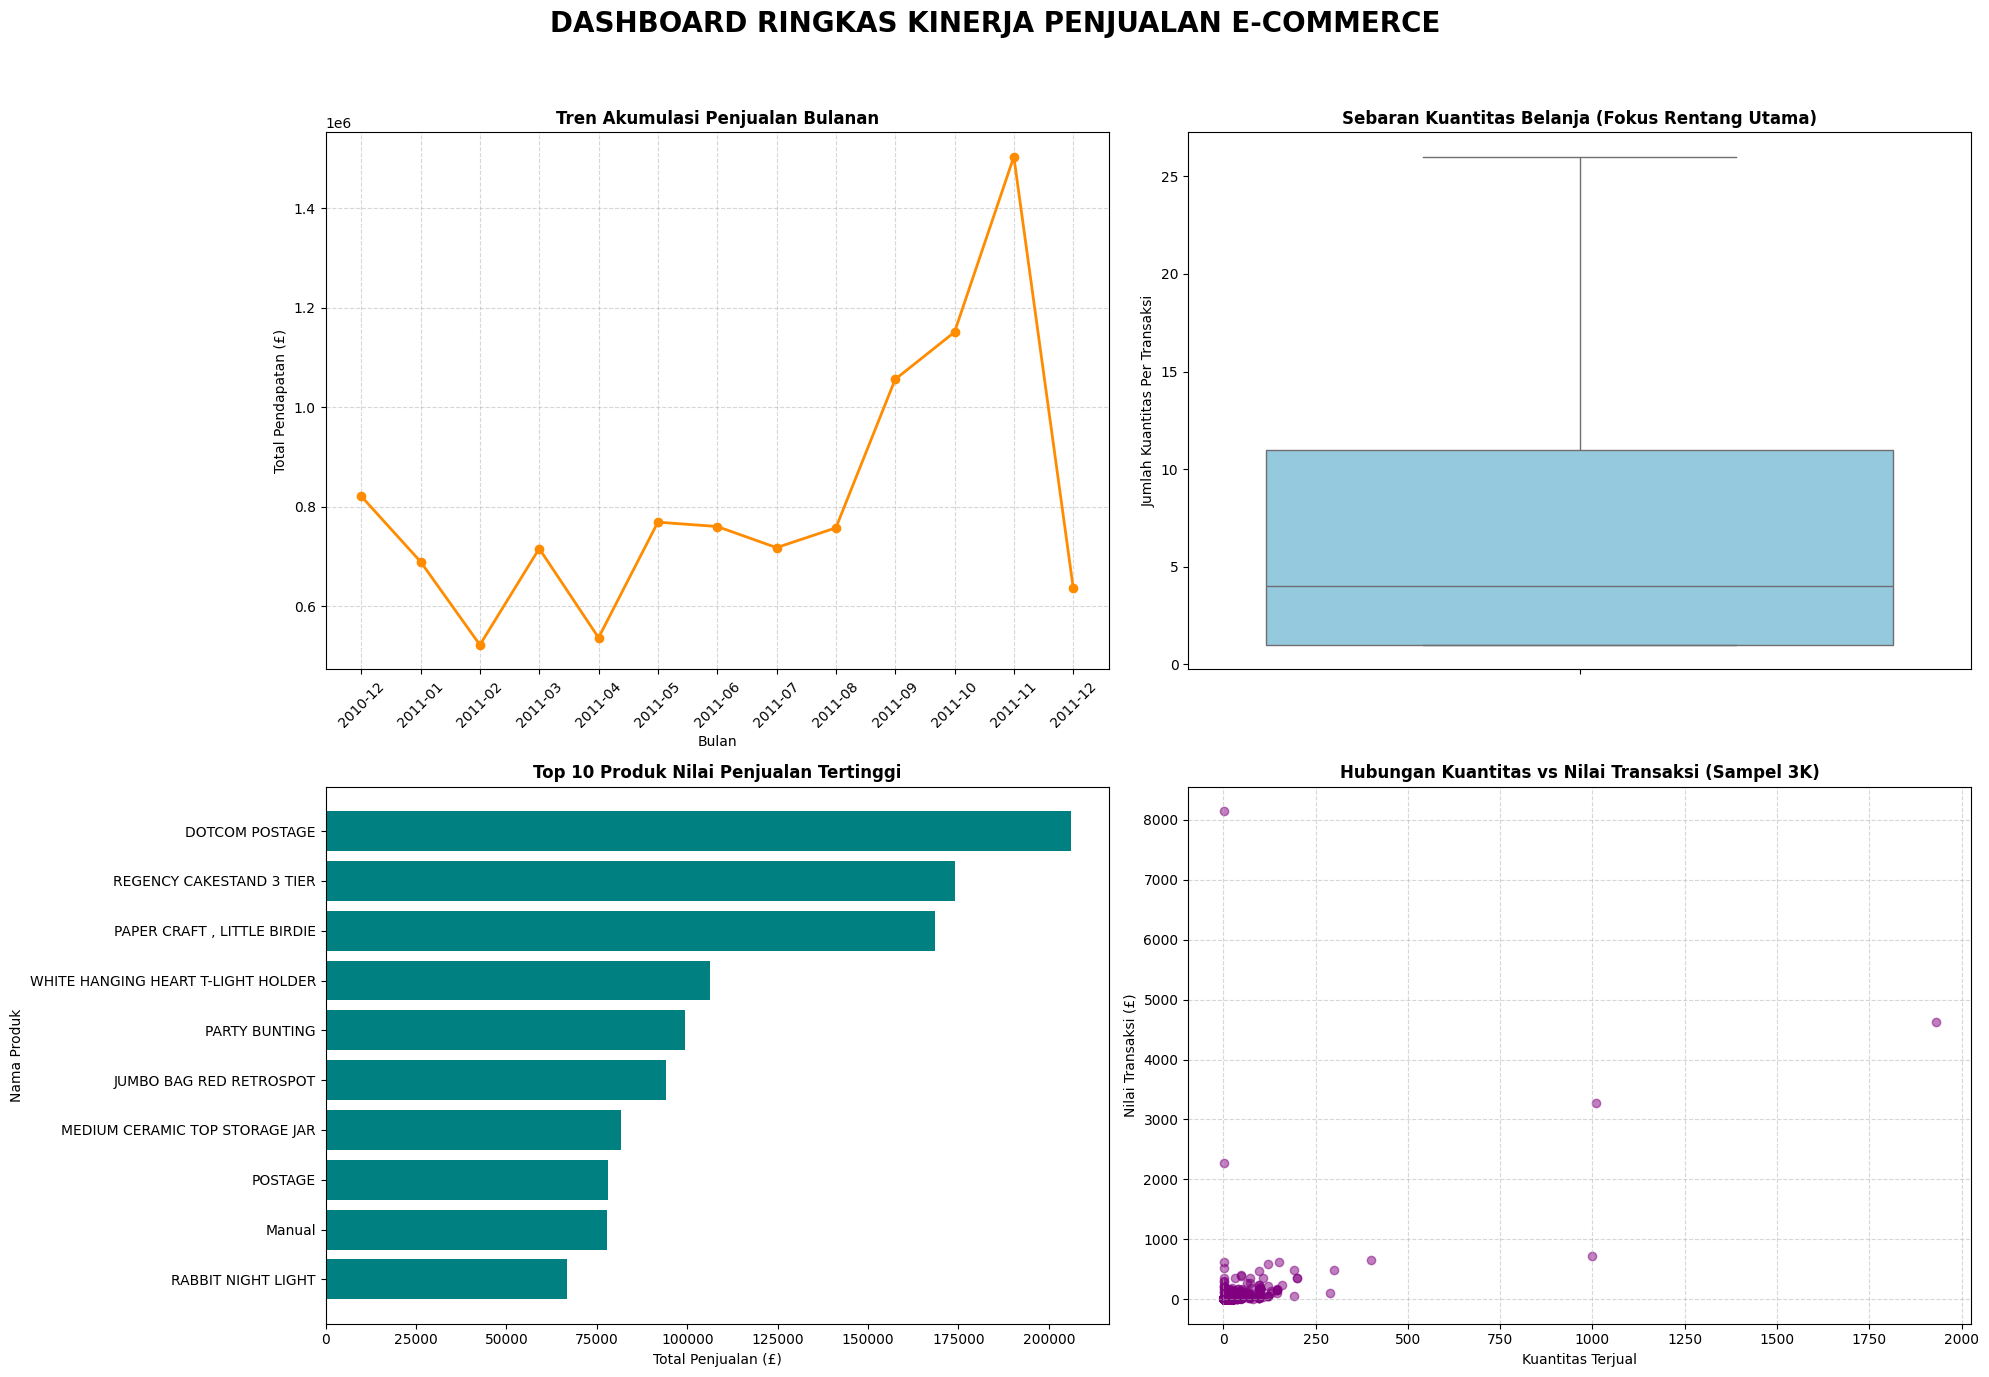

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Membuat dashboard ringkas (4 subplots dalam 1 figure)
fig, axes = plt.subplots(2, 2, figsize=(20, 14))
fig.suptitle('DASHBOARD RINGKAS KINERJA PENJUALAN E-COMMERCE', fontsize=20, fontweight='bold', y=0.98)

# 1. Tren Penjualan Bulanan (Line Chart)
tren_bulanan = penjualan.groupby("Month")["TotalSales"].sum()
axes[0, 0].plot(tren_bulanan.index, tren_bulanan.values, marker='o', color='darkorange', linewidth=2)
axes[0, 0].set_title("Tren Akumulasi Penjualan Bulanan", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Bulan")
axes[0, 0].set_ylabel("Total Pendapatan (£)")
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

# 2. Distribusi Kuantitas Belanja Utama (Boxplot tanpa Outlier)
sns.boxplot(data=penjualan, y="Quantity", showfliers=False, color='skyblue', ax=axes[0, 1])
axes[0, 1].set_title("Sebaran Kuantitas Belanja (Fokus Rentang Utama)", fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel("Jumlah Kuantitas Per Transaksi")

# 3. Top 10 Produk Terlaris (Bar Chart)
top_produk = penjualan.groupby("Description")["TotalSales"].sum().nlargest(10).sort_values()
axes[1, 0].barh(top_produk.index, top_produk.values, color='teal')
axes[1, 0].set_title("Top 10 Produk Nilai Penjualan Tertinggi", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Total Penjualan (£)")
axes[1, 0].set_ylabel("Nama Produk")

# 4. Hubungan Kuantitas vs Nilai Penjualan (Scatter Plot)
sampel_data = penjualan.sample(n=min(3000, len(penjualan)), random_state=42)
axes[1, 1].scatter(sampel_data["Quantity"], sampel_data["TotalSales"], alpha=0.5, color='purple')
axes[1, 1].set_title("Hubungan Kuantitas vs Nilai Transaksi (Sampel 3K)", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Kuantitas Terjual")
axes[1, 1].set_ylabel("Nilai Transaksi (£)")
axes[1, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

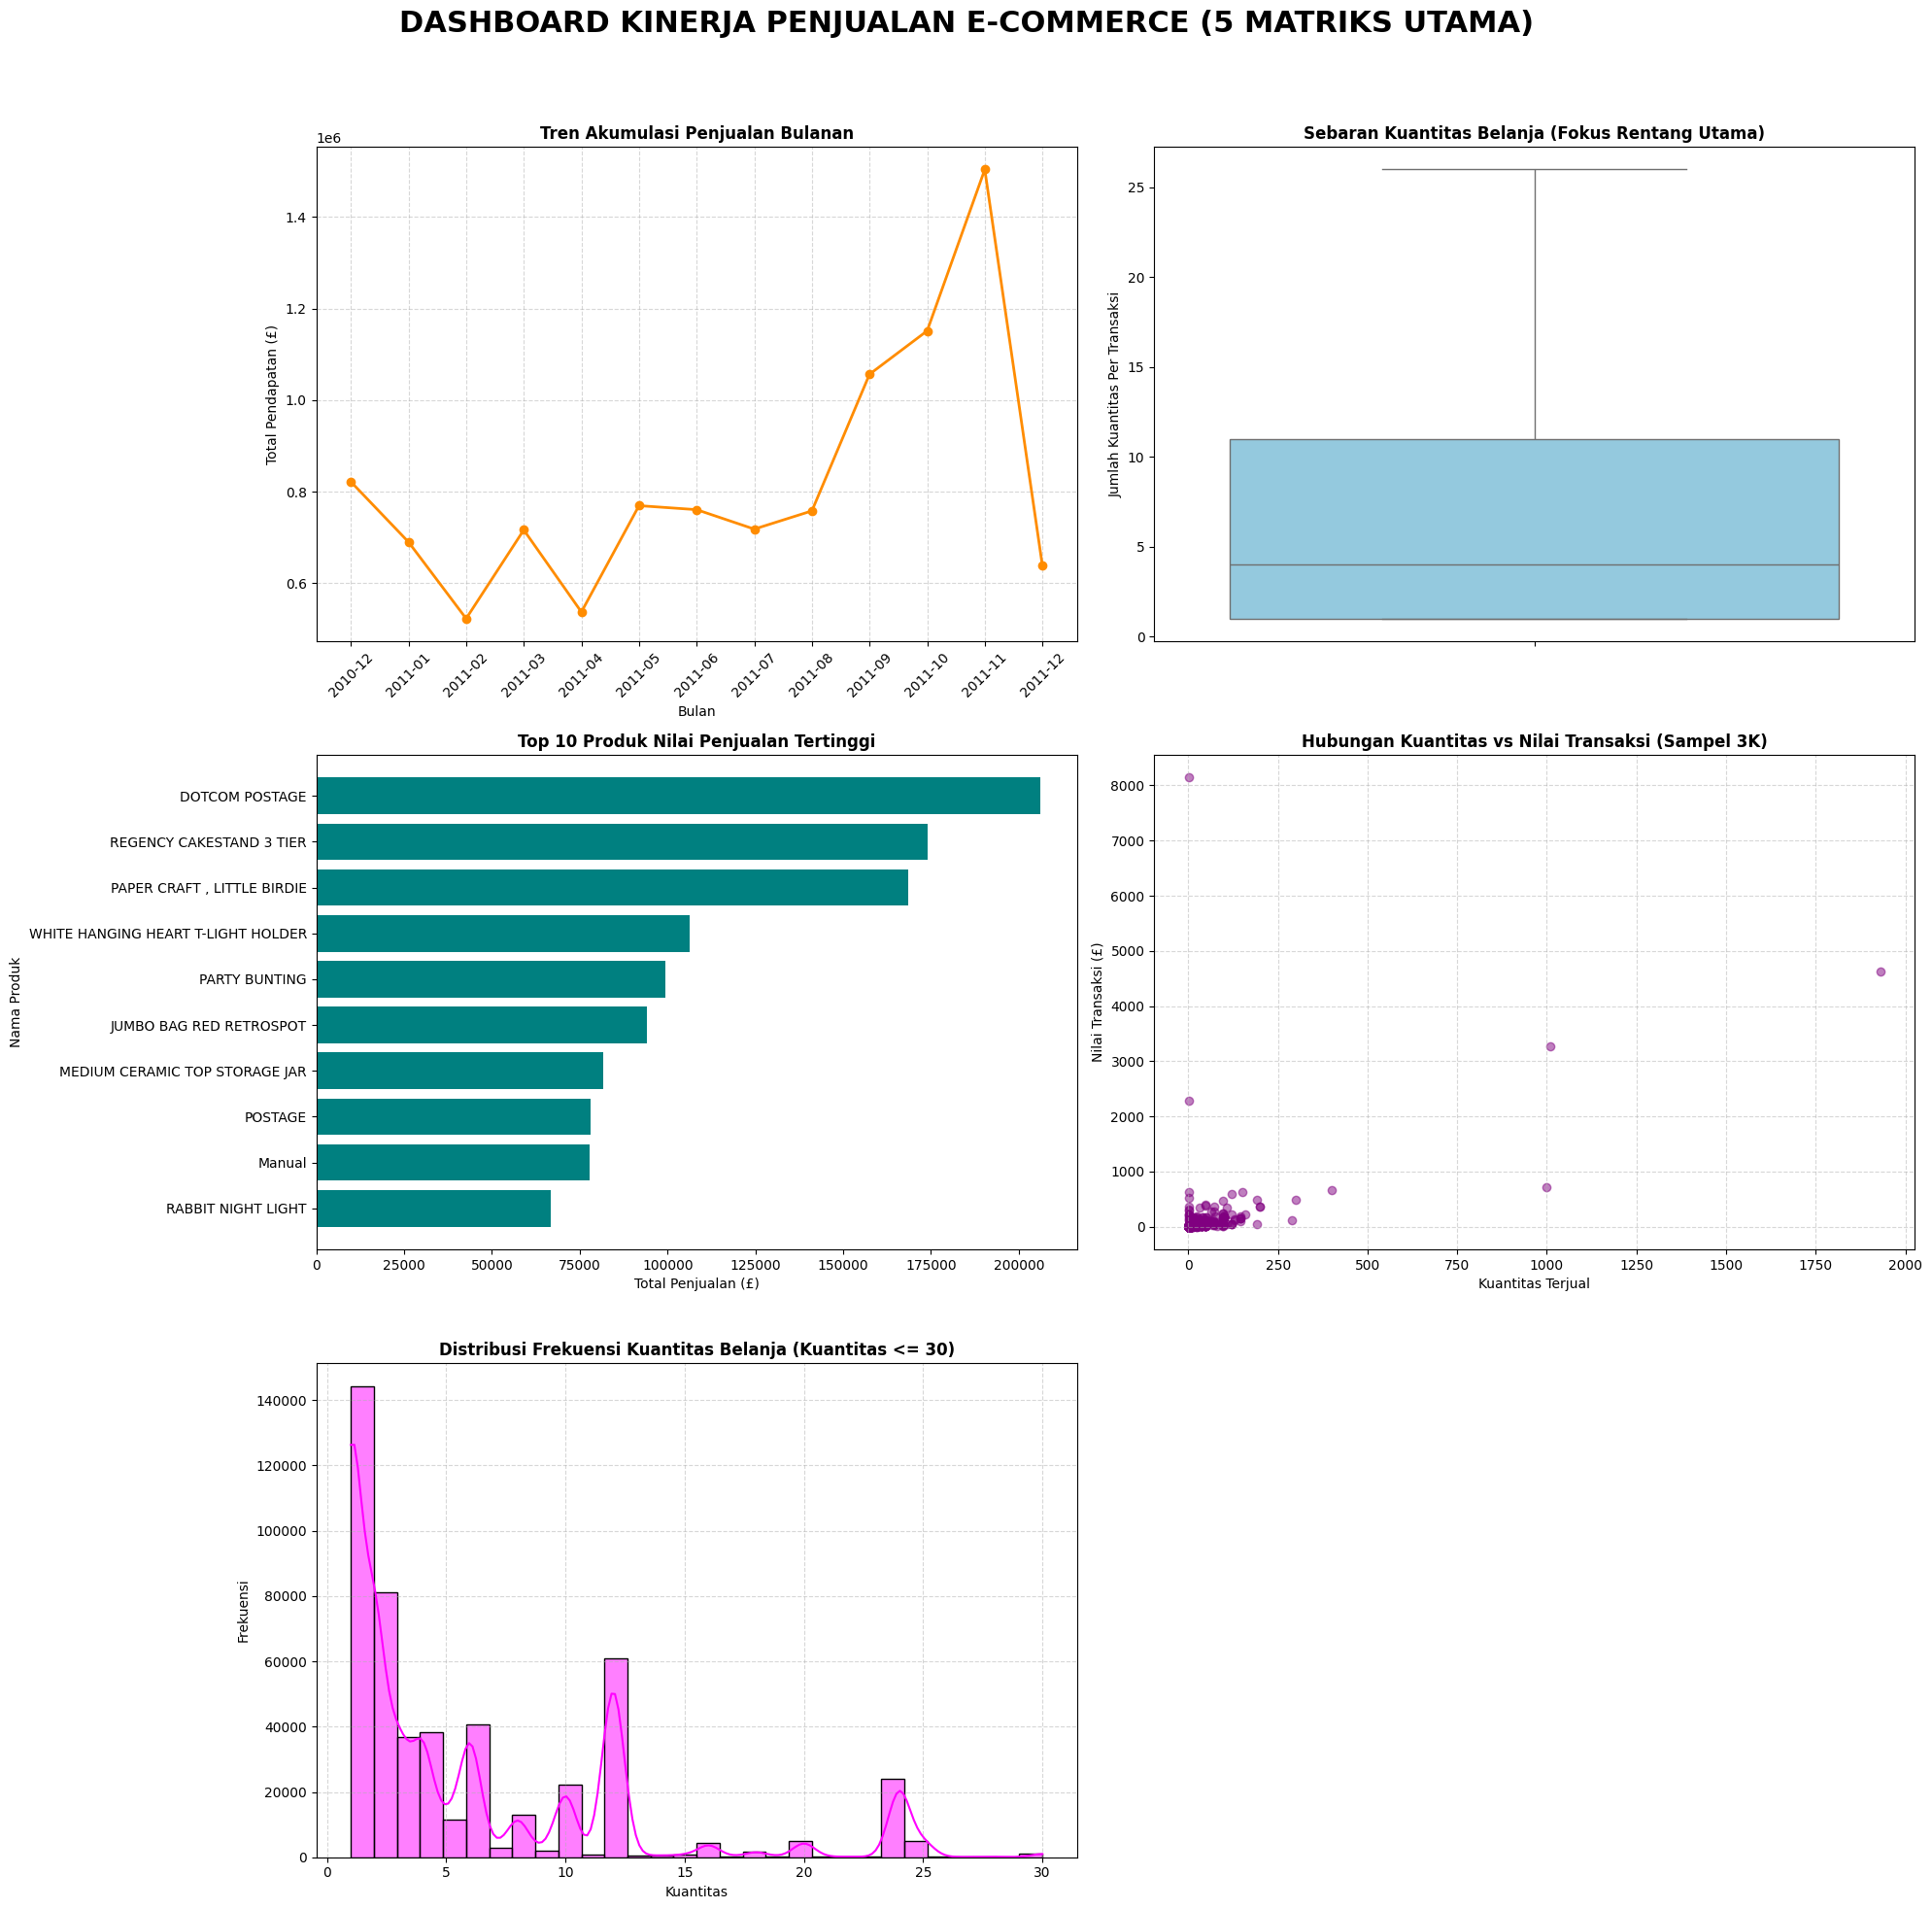

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Membuat dashboard ringkas yang kini mencakup 5 grafik utama (3 baris x 2 kolom, 1 subplot kosong/dihapus)
fig, axes = plt.subplots(3, 2, figsize=(20, 20))
fig.suptitle('DASHBOARD KINERJA PENJUALAN E-COMMERCE (5 MATRIKS UTAMA)', fontsize=22, fontweight='bold', y=0.98)

# 1. Tren Penjualan Bulanan (Line Chart)
tren_bulanan = penjualan.groupby("Month")["TotalSales"].sum()
axes[0, 0].plot(tren_bulanan.index, tren_bulanan.values, marker='o', color='darkorange', linewidth=2)
axes[0, 0].set_title("Tren Akumulasi Penjualan Bulanan", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Bulan")
axes[0, 0].set_ylabel("Total Pendapatan (£)")
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

# 2. Distribusi Kuantitas Belanja Utama (Boxplot tanpa Outlier)
sns.boxplot(data=penjualan, y="Quantity", showfliers=False, color='skyblue', ax=axes[0, 1])
axes[0, 1].set_title("Sebaran Kuantitas Belanja (Fokus Rentang Utama)", fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel("Jumlah Kuantitas Per Transaksi")

# 3. Top 10 Produk Terlaris (Bar Chart)
top_produk = penjualan.groupby("Description")["TotalSales"].sum().nlargest(10).sort_values()
axes[1, 0].barh(top_produk.index, top_produk.values, color='teal')
axes[1, 0].set_title("Top 10 Produk Nilai Penjualan Tertinggi", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Total Penjualan (£)")
axes[1, 0].set_ylabel("Nama Produk")

# 4. Hubungan Kuantitas vs Nilai Penjualan (Scatter Plot)
sampel_data = penjualan.sample(n=min(3000, len(penjualan)), random_state=42)
axes[1, 1].scatter(sampel_data["Quantity"], sampel_data["TotalSales"], alpha=0.5, color='purple')
axes[1, 1].set_title("Hubungan Kuantitas vs Nilai Transaksi (Sampel 3K)", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Kuantitas Terjual")
axes[1, 1].set_ylabel("Nilai Transaksi (£)")
axes[1, 1].grid(True, linestyle='--', alpha=0.5)

# 5. Distribusi Frekuensi Kuantitas (Histogram)
sns.histplot(data=penjualan[penjualan["Quantity"] <= 30], x="Quantity", bins=30, kde=True, color='magenta', ax=axes[2, 0])
axes[2, 0].set_title("Distribusi Frekuensi Kuantitas Belanja (Kuantitas <= 30)", fontsize=12, fontweight='bold')
axes[2, 0].set_xlabel("Kuantitas")
axes[2, 0].set_ylabel("Frekuensi")
axes[2, 0].grid(True, linestyle='--', alpha=0.5)

# Menghapus subplot ke-6 yang kosong agar layout tetap rapi
fig.delaxes(axes[2, 1])

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

```markdown
## 5. Laporan Rekomendasi Bisnis

**Kesimpulan & Rekomendasi:**
1. **Fokus Pasar Domestik & Internasional**: United Kingdom menyumbang porsi pendapatan terbesar. Namun, ekspansi pemasaran digital agresif ke pasar sekunder potensial (seperti Jerman dan Prancis) perlu dilakukan untuk mendiversifikasi basis risiko wilayah.
2. **Manajemen Stok Produk Kunci**: Produk-produk yang masuk dalam jajaran 10 besar penjualan harus diprioritaskan ketersediaannya (selalu restock) agar tidak kehilangan potensi profit akibat kehabisan stok.
3. **Optimalisasi Promosi Akhir Tahun**: Berdasarkan tren bulanan, terjadi lonjakan transaksi yang signifikan mendekati akhir tahun (Q4). Manajemen disarankan mengalokasikan anggaran promosi lebih besar pada bulan September - November untuk memaksimalkan momentum belanja tersebut.
4. **Mitigasi Outlier Transaksi**: Temuan outlier kuantitas super besar mengindikasikan adanya segmen pelanggan grosir (B2B). Tim penjualan harus membuat skema harga khusus grosir untuk mempertahankan loyalitas segmen pembeli volume tinggi ini.
```

### Referensi Sumber Data
Dataset diperoleh dari: [Kaggle - E-commerce Data](https://www.kaggle.com/datasets/carrie1/ecommerce-data)